<a href="https://colab.research.google.com/github/ayeshaalamexe/ds311-phishguard/blob/main/notebooks/04_product_lead.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 Product lead (Hassaan): URL-text model, robustness test and the PhishGuard app

**What this notebook does (runs top to bottom in Colab, seed 42):**
1. Loads and cleans the data in the same way as Ayesha and Sara.
2. Builds features from the **raw URL text only** (so the app works on any pasted URL).
3. Compares a feature model, a character n-gram TF-IDF model, and both together (5-fold CV).
4. Checks the alert threshold, the errors, and a **robustness test** (changed phishing URLs).
5. Saves the final model and writes the Streamlit app files into the `product/` folder.

Safety rule: URLs are only treated as text. Nothing here opens or visits a URL.

In [1]:
!pip install ucimlrepo -q

In [2]:
import warnings
warnings.filterwarnings("ignore")

import os, re, sys, json, time, shutil, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, ConfusionMatrixDisplay)

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)
SEED = 42

# sizes (same idea as the Mining Lead: 50,000 rows for model comparison)
EV_N = 50000      # rows used for 5-fold cross-validation
SAMPLE_N = 5000   # rows saved for the app dashboard
ROB_N = 5000      # phishing and legitimate URLs used in the robustness test

# folders
for folder in ["product", "product/models", "product/data", "product/results"]:
    os.makedirs(folder, exist_ok=True)
print("Folders ready. scikit-learn", sklearn.__version__)

Folders ready. scikit-learn 1.6.1


## Step 1: URL feature code
The next cell saves `product/url_features.py`. The same file is used here and inside the app,
so the model sees exactly the same kind of features in both places.

In [3]:
%%writefile product/url_features.py
"""URL feature code shared by the notebook and the Streamlit app.
Everything here works on the URL TEXT only. A URL is never opened or visited."""
import math
import re

import numpy as np
import pandas as pd

COMMON_TLDS = {"com", "org", "net", "edu", "gov"}
SHORTENERS = {"bit.ly", "tinyurl.com", "t.co", "goo.gl", "ow.ly", "is.gd",
              "buff.ly", "cutt.ly", "rebrand.ly", "shorturl.at"}
SUSPICIOUS_WORDS = ["login", "signin", "verify", "secure", "account", "update",
                    "bank", "confirm", "password", "paypal", "wallet", "webscr",
                    "free", "bonus"]

# the order of this list is the column order used by the model
FEATURE_NAMES = [
    "url_length", "domain_length", "is_ip", "tld_length", "num_subdomains",
    "num_dots_in_host", "num_hyphens_in_host", "num_digits_in_host",
    "longest_host_label", "num_letters", "letter_ratio", "num_digits",
    "digit_ratio", "num_equals", "num_qmark", "num_ampersand", "num_at",
    "num_other_special", "special_ratio", "num_slashes", "path_length",
    "query_length", "has_query", "num_percent", "has_obfuscation",
    "is_https", "has_www", "has_port", "entropy", "longest_digit_run",
    "num_suspicious_words", "is_shortener", "common_tld",
]

# plain-English names, used in the app
FEATURE_TEXT = {
    "url_length": "URL length",
    "domain_length": "Domain length",
    "is_ip": "Domain is an IP address",
    "tld_length": "Length of the ending (TLD)",
    "num_subdomains": "Number of sub-domains",
    "num_dots_in_host": "Dots in the domain",
    "num_hyphens_in_host": "Hyphens in the domain",
    "num_digits_in_host": "Digits in the domain",
    "longest_host_label": "Longest part of the domain",
    "num_letters": "Number of letters",
    "letter_ratio": "Share of letters",
    "num_digits": "Number of digits",
    "digit_ratio": "Share of digits",
    "num_equals": "Number of '=' signs",
    "num_qmark": "Number of '?' signs",
    "num_ampersand": "Number of '&' signs",
    "num_at": "Number of '@' signs",
    "num_other_special": "Other special characters",
    "special_ratio": "Share of non-letter, non-digit characters",
    "num_slashes": "Number of '/' signs",
    "path_length": "Path length",
    "query_length": "Query (after '?') length",
    "has_query": "Has a query part",
    "num_percent": "Number of '%' (encoded characters)",
    "has_obfuscation": "Has encoded characters",
    "is_https": "Uses https",
    "has_www": "Starts with www.",
    "has_port": "Has a port number",
    "entropy": "Randomness of characters (entropy)",
    "longest_digit_run": "Longest run of digits",
    "num_suspicious_words": "Suspicious words (login, verify, ...)",
    "is_shortener": "Is a link shortener",
    "common_tld": "Ends in .com/.org/.net/.edu/.gov",
}


def normalize_url(url):
    """Strip spaces. If no http(s):// was typed, assume https://."""
    url = str(url).strip()
    assumed = False
    if "://" not in url:
        url = "https://" + url
        assumed = True
    return url, assumed


def split_url(url):
    """Split a URL string into scheme, host, port and the rest (path + query)."""
    if "://" in url:
        scheme, rest = url.split("://", 1)
    else:
        scheme, rest = "", url
    m = re.search(r"[/?#]", rest)
    if m:
        netloc, after = rest[:m.start()], rest[m.start():]
    else:
        netloc, after = rest, ""
    host = netloc.split("@")[-1]
    port = ""
    mp = re.search(r":(\d+)$", host)
    if mp:
        port = mp.group(1)
        host = host[:mp.start()]
    return scheme.lower(), host.lower(), port, after


def entropy_of(text):
    if len(text) == 0:
        return 0.0
    total = 0.0
    for ch in set(text):
        p = text.count(ch) / len(text)
        total -= p * math.log2(p)
    return total


def url_features(url):
    """Return a dict with one number for each name in FEATURE_NAMES."""
    url = str(url).strip()
    n = max(len(url), 1)
    scheme, host, port, after = split_url(url)

    labels = host.split(".")
    is_ip = 1 if re.match(r"^\d{1,3}(\.\d{1,3}){3}$", host) else 0
    tld = labels[-1] if (len(labels) > 1 and not is_ip) else ""

    path_part = re.split(r"[?#]", after)[0]
    query = after.split("?", 1)[1].split("#")[0] if "?" in after else ""

    letters = sum(1 for c in url if c.isascii() and c.isalpha())
    digits = sum(1 for c in url if c.isdigit())
    other_special = sum(1 for c in url if not c.isalnum() and c not in "=?&")
    digit_runs = re.findall(r"\d+", url)
    lower = url.lower()

    f = {
        "url_length": len(url),
        "domain_length": len(host),
        "is_ip": is_ip,
        "tld_length": len(tld),
        "num_subdomains": 0 if is_ip else max(len(labels) - 2, 0),
        "num_dots_in_host": host.count("."),
        "num_hyphens_in_host": host.count("-"),
        "num_digits_in_host": sum(1 for c in host if c.isdigit()),
        "longest_host_label": max(len(x) for x in labels),
        "num_letters": letters,
        "letter_ratio": letters / n,
        "num_digits": digits,
        "digit_ratio": digits / n,
        "num_equals": url.count("="),
        "num_qmark": url.count("?"),
        "num_ampersand": url.count("&"),
        "num_at": url.count("@"),
        "num_other_special": other_special,
        "special_ratio": (len(url) - letters - digits) / n,
        "num_slashes": url.count("/"),
        "path_length": len(path_part),
        "query_length": len(query),
        "has_query": 1 if query else 0,
        "num_percent": url.count("%"),
        "has_obfuscation": 1 if "%" in url else 0,
        "is_https": 1 if scheme == "https" else 0,
        "has_www": 1 if host.startswith("www.") else 0,
        "has_port": 1 if port else 0,
        "entropy": entropy_of(url),
        "longest_digit_run": max((len(x) for x in digit_runs), default=0),
        "num_suspicious_words": sum(lower.count(w) for w in SUSPICIOUS_WORDS),
        "is_shortener": 1 if host in SHORTENERS else 0,
        "common_tld": 1 if tld in COMMON_TLDS else 0,
    }
    return {k: float(v) for k, v in f.items()}


def features_table(urls):
    """Many URLs -> a DataFrame with the columns in FEATURE_NAMES."""
    rows = [url_features(u) for u in urls]
    return pd.DataFrame(rows, columns=FEATURE_NAMES)


def strip_scheme(url):
    """Remove 'http://' or 'https://' (used to test how much the scheme matters)."""
    return re.sub(r"^[a-zA-Z]+://", "", str(url))


# ---------- scoring with the saved bundle ----------
# bundle = {"use": "features" | "tfidf" | "both", "feature_model": ..., "text_model": ...,
#           "legit_median": {...}}

def predict_scores(urls, bundle):
    """Risk score between 0 and 1 for each URL (1 = very likely phishing)."""
    urls = [str(u) for u in urls]
    use = bundle["use"]
    parts = []
    if use in ("features", "both"):
        parts.append(bundle["feature_model"].predict_proba(features_table(urls))[:, 1])
    if use in ("tfidf", "both"):
        parts.append(bundle["text_model"].predict_proba(urls)[:, 1])
    return np.mean(parts, axis=0)


def explain_features(url, bundle):
    """What-if table: set one feature at a time to the typical legitimate value and
    see how much the feature model's score drops. A big drop means that feature
    pushed the score up. (An approximation, one feature at a time.)"""
    model = bundle["feature_model"]
    x = features_table([url])
    base = model.predict_proba(x)[0, 1]
    x_many = pd.concat([x] * len(FEATURE_NAMES), ignore_index=True)
    for i, name in enumerate(FEATURE_NAMES):
        x_many.loc[i, name] = bundle["legit_median"][name]
    changed = model.predict_proba(x_many)[:, 1]
    out = pd.DataFrame({
        "feature": FEATURE_NAMES,
        "meaning": [FEATURE_TEXT[n] for n in FEATURE_NAMES],
        "value": [round(float(x.loc[0, n]), 3) for n in FEATURE_NAMES],
        "typical_legit_value": [round(float(bundle["legit_median"][n]), 3) for n in FEATURE_NAMES],
        "effect_on_score": base - changed,
    })
    return out.sort_values("effect_on_score", ascending=False).reset_index(drop=True)


def explain_text(url, bundle, top_n=5):
    """Character pieces of the URL that push the text model towards 'phishing'."""
    pipe = bundle["text_model"]
    vec = pipe.named_steps["tfidf"]
    lr = pipe.named_steps["lr"]
    x = vec.transform([url]).tocoo()
    names = vec.get_feature_names_out()
    contrib = x.data * lr.coef_[0][x.col]
    order = np.argsort(-contrib)[:top_n]
    return [(names[x.col[i]], float(contrib[i])) for i in order if contrib[i] > 0]

Writing product/url_features.py


In [4]:
sys.path.insert(0, "product")
import url_features as uf
importlib.reload(uf)

# quick test on two URLs
for u in ["https://www.southbankmosaics.com",
          "http://paypal-login.verify-account.example.xyz/secure/login.php?id=123456"]:
    print(u)
    print({k: round(v, 3) for k, v in uf.url_features(u).items() if v != 0})
    print()
print("Number of features:", len(uf.FEATURE_NAMES))

https://www.southbankmosaics.com
{'url_length': 32.0, 'domain_length': 24.0, 'tld_length': 3.0, 'num_subdomains': 1.0, 'num_dots_in_host': 2.0, 'longest_host_label': 16.0, 'num_letters': 27.0, 'letter_ratio': 0.844, 'num_other_special': 5.0, 'special_ratio': 0.156, 'num_slashes': 2.0, 'is_https': 1.0, 'has_www': 1.0, 'entropy': 3.929, 'num_suspicious_words': 1.0, 'common_tld': 1.0}

http://paypal-login.verify-account.example.xyz/secure/login.php?id=123456
{'url_length': 73.0, 'domain_length': 39.0, 'tld_length': 3.0, 'num_subdomains': 2.0, 'num_dots_in_host': 3.0, 'num_hyphens_in_host': 2.0, 'longest_host_label': 14.0, 'num_letters': 54.0, 'letter_ratio': 0.74, 'num_digits': 6.0, 'digit_ratio': 0.082, 'num_equals': 1.0, 'num_qmark': 1.0, 'num_other_special': 11.0, 'special_ratio': 0.178, 'num_slashes': 4.0, 'path_length': 17.0, 'query_length': 9.0, 'has_query': 1.0, 'entropy': 4.78, 'longest_digit_run': 6.0, 'num_suspicious_words': 6.0}

Number of features: 33


## Step 2: Load and clean the data (same cleaning as Ayesha)

In [5]:
from ucimlrepo import fetch_ucirepo

d = fetch_ucirepo(id=967)
df = pd.concat([d.data.features, d.data.targets], axis=1)
print("Raw shape:", df.shape)

df_clean = df.drop_duplicates(subset="URL", keep="first").reset_index(drop=True)
df_clean["is_phish"] = (df_clean["label"] == 0).astype(int)   # 1 = phishing, 0 = legitimate

print("Clean rows:", len(df_clean), "(Ayesha's report says 235,370)")
print(df_clean["is_phish"].value_counts())

Raw shape: (235795, 55)
Clean rows: 235370 (Ayesha's report says 235,370)
is_phish
0    134850
1    100520
Name: count, dtype: int64


## Step 3: Build features from the URL text
This loops over every URL, so it takes a minute or two.

In [6]:
t0 = time.time()
feat = uf.features_table(df_clean["URL"])
print("Feature table:", feat.shape, "| seconds:", round(time.time() - t0))
feat.head()

Feature table: (235370, 33) | seconds: 28


,url_length,domain_length,is_ip,tld_length,num_subdomains,num_dots_in_host,num_hyphens_in_host,num_digits_in_host,longest_host_label,num_letters,...,num_percent,has_obfuscation,is_https,has_www,has_port,entropy,longest_digit_run,num_suspicious_words,is_shortener,common_tld
0,32.0,24.0,0.0,3.0,1.0,2.0,0.0,0.0,16.0,27.0,...,0.0,0.0,1.0,1.0,0.0,3.929229,0.0,1.0,0.0,1.0
1,24.0,16.0,0.0,2.0,1.0,2.0,1.0,0.0,9.0,18.0,...,0.0,0.0,1.0,1.0,0.0,3.970176,0.0,0.0,0.0,0.0
2,30.0,22.0,0.0,2.0,2.0,3.0,0.0,0.0,12.0,24.0,...,0.0,0.0,1.0,1.0,0.0,4.164735,0.0,0.0,0.0,0.0
3,27.0,19.0,0.0,3.0,1.0,2.0,0.0,0.0,11.0,22.0,...,0.0,0.0,1.0,1.0,0.0,4.060262,0.0,0.0,0.0,1.0
4,34.0,26.0,0.0,3.0,1.0,2.0,0.0,0.0,18.0,29.0,...,0.0,0.0,1.0,1.0,0.0,3.917626,0.0,0.0,0.0,1.0


### Check: do my features agree with the dataset's own columns?
The dataset has its own URL columns. They were computed with slightly different rules, so we expect
high agreement but not always 100%.

In [7]:
pairs = [("url_length", "URLLength"), ("domain_length", "DomainLength"),
         ("num_digits", "NoOfDegitsInURL"), ("num_subdomains", "NoOfSubDomain"),
         ("is_https", "IsHTTPS")]
rows = []
for mine, theirs in pairs:
    rows.append({"my_feature": mine, "dataset_column": theirs,
                 "exact_match_percent": round(100 * (feat[mine] == df_clean[theirs]).mean(), 1),
                 "correlation": round(feat[mine].corr(df_clean[theirs].astype(float)), 4)})
agree = pd.DataFrame(rows)
agree

,my_feature,dataset_column,exact_match_percent,correlation
0,url_length,URLLength,20.6,1.0000
1,domain_length,DomainLength,100.0,0.9998
2,num_digits,NoOfDegitsInURL,99.5,1.0000
3,num_subdomains,NoOfSubDomain,99.7,0.9856
4,is_https,IsHTTPS,99.8,0.9939


## Step 4: Look at my features by class (EDA for the dashboard)

In [8]:
y_all = df_clean["is_phish"]
by_class = feat.groupby(y_all.map({0: "legitimate", 1: "phishing"})).mean().T.round(3)
by_class

is_phish,legitimate,phishing
url_length,27.229,46.221
domain_length,19.229,24.441
is_ip,0.000,0.006
tld_length,2.723,2.803
num_subdomains,1.162,1.157
num_dots_in_host,2.162,2.169
num_hyphens_in_host,0.083,0.546
num_digits_in_host,0.051,1.988
longest_host_label,10.895,13.666
num_letters,21.933,34.236


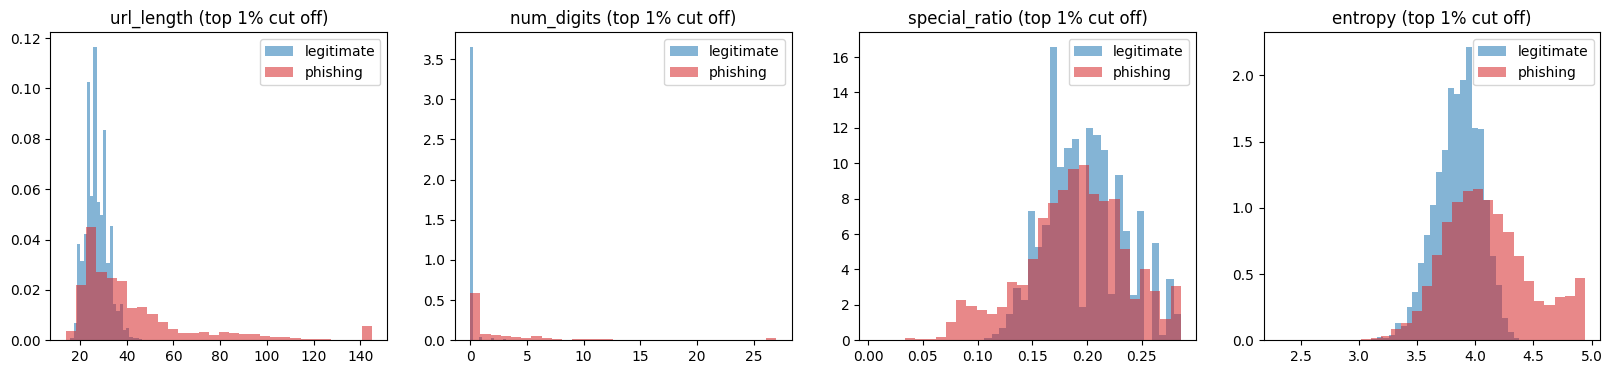

Share of https:  legitimate 1.0 | phishing 0.486
Share with www.: legitimate 1.0 | phishing 0.415


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, ["url_length", "num_digits", "special_ratio", "entropy"]):
    upper = feat[c].quantile(0.99)
    for label, color, name in [(0, "tab:blue", "legitimate"), (1, "tab:red", "phishing")]:
        ax.hist(feat.loc[y_all == label, c].clip(upper=upper), bins=30, alpha=0.55,
                density=True, color=color, label=name)
    ax.set_title(c + " (top 1% cut off)")
    ax.legend()
plt.show()
print("Share of https:  legitimate", round(feat.loc[y_all == 0, "is_https"].mean(), 3),
      "| phishing", round(feat.loc[y_all == 1, "is_https"].mean(), 3))
print("Share with www.: legitimate", round(feat.loc[y_all == 0, "has_www"].mean(), 3),
      "| phishing", round(feat.loc[y_all == 1, "has_www"].mean(), 3))

In [10]:
# save a small random sample for the app dashboard
idx_small, _ = train_test_split(np.arange(len(df_clean)), train_size=SAMPLE_N,
                                stratify=y_all, random_state=SEED)
sample = feat.iloc[idx_small].copy()
sample.insert(0, "url", df_clean["URL"].iloc[idx_small].values)
sample["is_phish"] = y_all.iloc[idx_small].values
sample.to_csv("product/data/sample_urls.csv", index=False)
print("Saved dashboard sample:", sample.shape)

Saved dashboard sample: (5000, 35)


## Step 5: Which of my features carry the most information?
Mutual information on the 50,000-row sample (Week 5 idea, same as Sara used).

In [11]:
# the 50,000-row sample used for all cross-validation below
ev_idx, _ = train_test_split(np.arange(len(df_clean)), train_size=EV_N,
                             stratify=y_all, random_state=SEED)
X_feat = feat.iloc[ev_idx].reset_index(drop=True)
X_url = df_clean["URL"].iloc[ev_idx].reset_index(drop=True)
y_ev = y_all.iloc[ev_idx].reset_index(drop=True)
print("Evaluation sample:", len(y_ev), "| phishing share:", round(y_ev.mean(), 3))

mi = mutual_info_classif(X_feat, y_ev, random_state=SEED)
ranking = pd.DataFrame({"feature": uf.FEATURE_NAMES, "meaning": [uf.FEATURE_TEXT[n] for n in uf.FEATURE_NAMES],
                        "mutual_info": mi}).sort_values("mutual_info", ascending=False).reset_index(drop=True)
ranking.to_csv("product/results/feature_ranking_url_text.csv", index=False)
ranking.head(12).round(4)

Evaluation sample: 50000 | phishing share: 0.427


,feature,meaning,mutual_info
0,has_www,Starts with www.,0.2772
1,num_slashes,Number of '/' signs,0.2767
2,path_length,Path length,0.2748
3,is_https,Uses https,0.2368
4,letter_ratio,Share of letters,0.2236
5,num_other_special,Other special characters,0.2018
6,special_ratio,"Share of non-letter, non-digit characters",0.1923
7,entropy,Randomness of characters (entropy),0.1774
8,digit_ratio,Share of digits,0.1731
9,num_digits,Number of digits,0.1680


## Step 6: Compare the URL-text models (stratified 5-fold CV)
- **Feature model**: gradient boosting on the handcrafted URL features.
- **Text model**: TF-IDF on character 2- to 4-grams of the URL + logistic regression.
- **Both**: the average of the two scores.

We also test two versions that do not see the scheme (`http`/`https`), because in this dataset every
legitimate URL is https and that can act as a shortcut (the same worry as Sara's IsHTTPS check).
The TF-IDF step is inside the pipeline, so it is fitted on training folds only.

In [12]:
def make_feature_model():
    return HistGradientBoostingClassifier(random_state=SEED)

def make_text_model():
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(2, 4), max_features=50000,
                                  lowercase=False, sublinear_tf=True, dtype=np.float32)),
        ("lr", LogisticRegression(C=10, solver="liblinear")),
    ])

def score_table(y, p, name, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"model": name,
            "roc_auc": roc_auc_score(y, p),
            "precision": precision_score(y, pred),
            "recall": recall_score(y, pred),
            "f1": f1_score(y, pred),
            "missed_phish_per_1000": 1000 * fn / (fn + tp),     # per 1,000 phishing URLs
            "false_alarms_per_1000": 1000 * fp / (fp + tn)}     # per 1,000 legitimate URLs

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = {}   # out-of-fold scores for each model

t0 = time.time()
oof["Feature model (GB)"] = cross_val_predict(make_feature_model(), X_feat, y_ev, cv=cv5,
                                              method="predict_proba")[:, 1]
print("done feature model | seconds:", round(time.time() - t0))

oof["Feature model, no is_https"] = cross_val_predict(make_feature_model(), X_feat.drop(columns=["is_https"]),
                                                      y_ev, cv=cv5, method="predict_proba")[:, 1]
print("done feature model without is_https")

oof["Text model (TF-IDF + LR)"] = cross_val_predict(make_text_model(), X_url, y_ev, cv=cv5,
                                                    method="predict_proba")[:, 1]
print("done text model | seconds:", round(time.time() - t0))

X_url_noscheme = X_url.apply(uf.strip_scheme)
oof["Text model, no scheme"] = cross_val_predict(make_text_model(), X_url_noscheme, y_ev, cv=cv5,
                                                 method="predict_proba")[:, 1]
print("done text model without scheme")

oof["Both (average)"] = (oof["Feature model (GB)"] + oof["Text model (TF-IDF + LR)"]) / 2

comparison = pd.DataFrame([score_table(y_ev, p, name) for name, p in oof.items()])
comparison["train_rows"] = len(y_ev)
comparison.to_csv("product/results/url_model_comparison.csv", index=False)
comparison.round(4)

done feature model | seconds: 7
done feature model without is_https
done text model | seconds: 50
done text model without scheme


,model,roc_auc,precision,recall,f1,missed_phish_per_1000,false_alarms_per_1000,train_rows
0,Feature model (GB),0.9982,0.9998,0.9955,0.9976,4.4956,0.1745,50000
1,"Feature model, no is_https",0.9986,0.9992,0.9949,0.9970,5.0576,0.6284,50000
2,Text model (TF-IDF + LR),0.9989,1.0000,0.9916,0.9957,8.4293,0.0349,50000
3,"Text model, no scheme",0.9357,0.9396,0.8153,0.8731,184.6961,39.0630,50000
4,Both (average),0.9990,1.0000,0.9956,0.9978,4.4488,0.0000,50000


In [13]:
# choose the scoring rule for the app: best ROC-AUC among the three full-feature options
options = {"features": "Feature model (GB)", "tfidf": "Text model (TF-IDF + LR)", "both": "Both (average)"}
auc_of = {k: roc_auc_score(y_ev, oof[v]) for k, v in options.items()}
USE = max(auc_of, key=auc_of.get)
print({k: round(v, 5) for k, v in auc_of.items()})
print("Chosen for the app:", USE)
final_oof = oof[options[USE]]

{'features': np.float64(0.99824), 'tfidf': np.float64(0.99892), 'both': np.float64(0.99896)}
Chosen for the app: both


## Step 7: Choosing the alert threshold (cost of a missed phish)
A lower threshold catches more phishing but raises more false alarms.

In [14]:
rows = []
for thr in [0.1, 0.2, 0.3, 0.5, 0.7, 0.9]:
    r = score_table(y_ev, final_oof, "x", thr)
    rows.append({"threshold": thr,
                 "phishing_caught_percent": round(100 * r["recall"], 2),
                 "missed_phish_per_1000": round(r["missed_phish_per_1000"], 1),
                 "false_alarms_per_1000": round(r["false_alarms_per_1000"], 1),
                 "precision_percent": round(100 * r["precision"], 2)})
thr_table = pd.DataFrame(rows)
thr_table.to_csv("product/results/threshold_table.csv", index=False)
thr_table

,threshold,phishing_caught_percent,missed_phish_per_1000,false_alarms_per_1000,precision_percent
0,0.1,99.63,3.7,1.3,99.83
1,0.2,99.58,4.2,0.3,99.95
2,0.3,99.57,4.3,0.1,99.99
3,0.5,99.56,4.4,0.0,100.00
4,0.7,99.19,8.1,0.0,100.00
5,0.9,98.68,13.2,0.0,100.00


## Step 8: Confusion matrix, ROC curve and error analysis

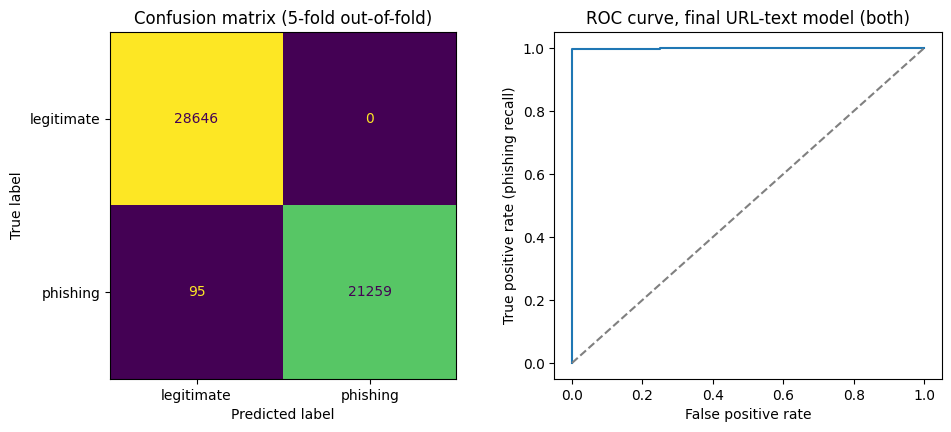

In [15]:
pred = (final_oof >= 0.5).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_ev, pred, display_labels=["legitimate", "phishing"],
                                        ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (5-fold out-of-fold)")
fpr, tpr, _ = roc_curve(y_ev, final_oof)
axes[1].plot(fpr, tpr)
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (phishing recall)")
axes[1].set_title("ROC curve, final URL-text model (" + USE + ")")
plt.savefig("product/results/confusion_roc_final.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# look at the mistakes (text only, never open them)
errors = pd.DataFrame({"URL": X_url, "is_phish": y_ev, "score": final_oof})
missed = errors[(errors["is_phish"] == 1) & (errors["score"] < 0.5)].sort_values("score")
false_alarm = errors[(errors["is_phish"] == 0) & (errors["score"] >= 0.5)].sort_values("score", ascending=False)
print("Missed phishing URLs:", len(missed), "| False alarms:", len(false_alarm))

pd.concat([missed.head(20).assign(kind="missed phishing"),
           false_alarm.head(20).assign(kind="false alarm")]).to_csv(
    "product/results/error_examples.csv", index=False)

print("\nMissed phishing (lowest scores):")
for u in missed["URL"].head(8):
    print("  ", u)
print("\nFalse alarms (highest scores):")
for u in false_alarm["URL"].head(8):
    print("  ", u)

Missed phishing URLs: 95 | False alarms: 0

Missed phishing (lowest scores):
   https://www.ur.link
   https://www.peb.co.il
   https://www.cuag.fit
   https://www.renatika.com
   https://www.alullanos.com
   https://www.orderedami.com
   https://www.hireamed.com
   https://www.kwresearch.com.au

False alarms (highest scores):


## Step 9: Robustness test (expert module)
We train on 80% of the data, then **change** phishing URLs in the 20% test part in ways a phisher could
try, and measure how many are still caught. We apply the same change to legitimate URLs to see how many
false alarms it causes. (All changes are text edits. Nothing is visited.)

In [17]:
def raw_parts(url):
    # prefix (like https://), host (with port) and the rest of the URL
    if "://" in url:
        prefix, remainder = url.split("://", 1)
        prefix = prefix + "://"
    else:
        prefix, remainder = "", url
    m = re.search(r"[/?#]", remainder)
    if m:
        return prefix, remainder[:m.start()], remainder[m.start():]
    return prefix, remainder, ""

rng = np.random.RandomState(SEED)
letters_digits = list("abcdefghijklmnopqrstuvwxyz0123456789")

def p_force_https(u):
    prefix, host, rest = raw_parts(u)
    return "https://" + host + rest

def p_homepage_only(u):
    prefix, host, rest = raw_parts(u)
    return prefix + host

def p_add_www(u):
    prefix, host, rest = raw_parts(u)
    if host.startswith("www.") or re.match(r"^\d+\.\d+\.\d+\.\d+", host):
        return u
    return prefix + "www." + host + rest

def p_extra_subdomains(u):
    prefix, host, rest = raw_parts(u)
    return prefix + "secure.login." + host + rest

def p_homoglyphs(u):
    prefix, host, rest = raw_parts(u)
    return prefix + host.replace("o", "0").replace("l", "1") + rest

def p_add_query(u):
    prefix, host, rest = raw_parts(u)
    joiner = "&" if "?" in rest else "?"
    return prefix + host + rest + joiner + "id=" + str(rng.randint(10000, 99999))

def p_toggle_slash(u):
    return u[:-1] if u.endswith("/") else u + "/"

def p_shortener(u):
    return "https://bit.ly/" + "".join(rng.choice(letters_digits, 7))

perturbations = {
    "force https": p_force_https,
    "homepage only (drop path and query)": p_homepage_only,
    "add www.": p_add_www,
    "extra sub-domains (secure.login.)": p_extra_subdomains,
    "homoglyphs (o to 0, l to 1 in domain)": p_homoglyphs,
    "add random query (?id=...)": p_add_query,
    "toggle trailing slash": p_toggle_slash,
    "link shortener (bit.ly/...)": p_shortener,
}
print(len(perturbations), "changes ready")

8 changes ready


In [18]:
# train on 80%, keep 20% as the test part
tr_idx, te_idx = train_test_split(np.arange(len(df_clean)), test_size=0.2,
                                  stratify=y_all, random_state=SEED)
t0 = time.time()
rob_feature_model = make_feature_model().fit(feat.iloc[tr_idx], y_all.iloc[tr_idx])
rob_text_model = make_text_model().fit(df_clean["URL"].iloc[tr_idx].tolist(), y_all.iloc[tr_idx])
print("trained | seconds:", round(time.time() - t0))

# a sample of test URLs
te_y = y_all.iloc[te_idx]
phish_urls = df_clean["URL"].iloc[te_idx][te_y == 1].sample(ROB_N, random_state=SEED).tolist()
legit_urls = df_clean["URL"].iloc[te_idx][te_y == 0].sample(ROB_N, random_state=SEED).tolist()

def all_scores(urls):
    pf = rob_feature_model.predict_proba(uf.features_table(urls))[:, 1]
    pt = rob_text_model.predict_proba(urls)[:, 1]
    return {"features": pf, "tfidf": pt, "both": (pf + pt) / 2}

rows = []
tests = [("none (original URLs)", lambda u: u)] + list(perturbations.items())
for name, fn in tests:
    s_phish = all_scores([fn(u) for u in phish_urls])
    s_legit = all_scores([fn(u) for u in legit_urls])
    for model_name in ["features", "tfidf", "both"]:
        rows.append({"change": name, "model": model_name,
                     "phishing_still_caught_percent": round(100 * (s_phish[model_name] >= 0.5).mean(), 1),
                     "legit_flagged_percent": round(100 * (s_legit[model_name] >= 0.5).mean(), 1)})
    print("done:", name)

rob_all = pd.DataFrame(rows)
rob_all.to_csv("product/results/robustness_all_models.csv", index=False)

rob_chosen = rob_all[rob_all["model"] == USE].drop(columns="model")
rob_chosen.to_csv("product/results/robustness_table.csv", index=False)
print("Robustness table for the chosen model (" + USE + "):")
rob_chosen

trained | seconds: 31
done: none (original URLs)
done: force https
done: homepage only (drop path and query)
done: add www.
done: extra sub-domains (secure.login.)
done: homoglyphs (o to 0, l to 1 in domain)
done: add random query (?id=...)
done: toggle trailing slash
done: link shortener (bit.ly/...)
Robustness table for the chosen model (both):


,change,phishing_still_caught_percent,legit_flagged_percent
2,none (original URLs),99.7,0.0
5,force https,65.4,0.0
8,homepage only (drop path and query),98.4,0.0
11,add www.,98.8,0.0
14,extra sub-domains (secure.login.),100.0,100.0
17,"homoglyphs (o to 0, l to 1 in domain)",99.7,0.0
20,add random query (?id=...),99.7,0.1
23,toggle trailing slash,99.8,99.5
26,link shortener (bit.ly/...),100.0,100.0


In [19]:
# examples of changed URLs (text only)
example = phish_urls[0]
print("original:", example)
for name, fn in perturbations.items():
    print(name.ljust(40), fn(example))

original: https://onliineebpi1z-28674.web.app/
force https                              https://onliineebpi1z-28674.web.app/
homepage only (drop path and query)      https://onliineebpi1z-28674.web.app
add www.                                 https://www.onliineebpi1z-28674.web.app/
extra sub-domains (secure.login.)        https://secure.login.onliineebpi1z-28674.web.app/
homoglyphs (o to 0, l to 1 in domain)    https://0n1iineebpi1z-28674.web.app/
add random query (?id=...)               https://onliineebpi1z-28674.web.app/?id=90892
toggle trailing slash                    https://onliineebpi1z-28674.web.app
link shortener (bit.ly/...)              https://bit.ly/anaxkcm


## Step 10: Train the final models on all cleaned rows and save the bundle
As in Sara's notebook, the performance of this model is the cross-validation score from Step 6,
not a score on its own training data.

In [20]:
t0 = time.time()
final_feature_model = make_feature_model().fit(feat, y_all)
final_text_model = make_text_model().fit(df_clean["URL"].tolist(), y_all)
print("trained on", len(df_clean), "rows | seconds:", round(time.time() - t0))

# the saved vectorizer keeps a huge list of dropped n-grams; delete it so the file stays small
vec = final_text_model.named_steps["tfidf"]
if hasattr(vec, "stop_words_"):
    del vec.stop_words_

legit_median = feat[y_all == 0].median().to_dict()   # used by the 'what-if' explanation in the app

bundle = {"use": USE, "feature_model": final_feature_model, "text_model": final_text_model,
          "legit_median": legit_median, "feature_names": uf.FEATURE_NAMES,
          "sklearn_version": sklearn.__version__}
joblib.dump(bundle, "product/models/phishguard_bundle.joblib", compress=3)
json.dump({"use": USE, "threshold_high": 0.7, "threshold_medium": 0.3},
          open("product/models/config.json", "w"))
print("Saved. Size (MB):", round(os.path.getsize("product/models/phishguard_bundle.joblib") / 1e6, 2))

trained on 235370 rows | seconds: 39
Saved. Size (MB): 0.97


## Step 11: Test the saved bundle the way the app uses it

In [21]:
loaded = joblib.load("product/models/phishguard_bundle.joblib")

test_urls = ["https://www.google.com",
             "https://www.wikipedia.org",
             "http://secure-paypal-login.verify-account-update.xyz/signin.php?id=48392",
             "http://192.168.10.5/bank/login.php?user=abc&pass=123",
             "https://github.com/ayeshaalamexe/ds311-phishguard"]
scores = uf.predict_scores(test_urls, loaded)
for u, s in zip(test_urls, scores):
    print(str(round(100 * s, 1)).rjust(5), "/ 100  ", u)

print()
print("Why was the 2nd-last URL scored this way? (feature what-if)")
uf.explain_features(test_urls[2], loaded).head(6)

  0.1 / 100   https://www.google.com
  0.1 / 100   https://www.wikipedia.org
100.0 / 100   http://secure-paypal-login.verify-account-update.xyz/signin.php?id=48392
100.0 / 100   http://192.168.10.5/bank/login.php?user=abc&pass=123
100.0 / 100   https://github.com/ayeshaalamexe/ds311-phishguard

Why was the 2nd-last URL scored this way? (feature what-if)


,feature,meaning,value,typical_legit_value,effect_on_score
0,has_www,Starts with www.,0.0,1.0,1.055744e-09
1,num_slashes,Number of '/' signs,3.0,2.0,2.957040e-10
2,url_length,URL length,72.0,27.0,0.000000e+00
3,domain_length,Domain length,45.0,19.0,0.000000e+00
4,is_ip,Domain is an IP address,0.0,0.0,0.000000e+00
5,num_dots_in_host,Dots in the domain,2.0,2.0,0.000000e+00


In [22]:
print("Text pieces for the same URL:", uf.explain_text(test_urls[2], loaded))

Text pieces for the same URL: [('p://', 0.7434794863123682), ('tp:/', 0.743468168576499), ('ttp:', 0.743468168576499), ('p:', 0.743468168576499), ('p:/', 0.743468168576499)]


**Reading the test above:** the model learned from this dataset, where legitimate URLs are mostly short
home pages. A harmless but long deep link (like a GitHub repo page) can therefore score higher than you expect.
This is a limitation of the data, and it is written in the report.

## Step 12: Write the Streamlit app files
The next cells save `product/app.py` and `product/requirements.txt`.

In [23]:
%%writefile product/app.py
# PhishGuard: Streamlit app (Product Lead: Hassaan)
# The app only reads the URL as TEXT. It never opens or visits a URL.
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import streamlit as st

BASE = Path(__file__).parent          # the product/ folder
ROOT = BASE.parent                    # the repo folder (has results/ from the Mining Lead)
sys.path.insert(0, str(BASE))

from url_features import (FEATURE_NAMES, FEATURE_TEXT, normalize_url, url_features,
                          predict_scores, explain_features, explain_text)

st.set_page_config(page_title="PhishGuard", page_icon="🛡️", layout="wide")


@st.cache_resource
def load_bundle():
    return joblib.load(BASE / "models" / "phishguard_bundle.joblib")


@st.cache_data
def load_csv(path):
    return pd.read_csv(path)


def show_csv_if_exists(path, title):
    if Path(path).exists():
        st.subheader(title)
        st.dataframe(load_csv(path), hide_index=True)


def show_image_if_exists(path, caption):
    if Path(path).exists():
        st.image(str(path), caption=caption)


bundle = load_bundle()

st.title("🛡️ PhishGuard: Phishing URL Miner")
st.caption("Paste a URL to get a risk score. PhishGuard only reads the text of the URL. "
           "It never opens the link.")

tab1, tab2, tab3, tab4 = st.tabs(["Check a URL", "Dashboard", "Cluster explorer", "About"])

# ------------------------------------------------------------------ tab 1
with tab1:
    raw = st.text_input("URL to check", placeholder="https://example.com/login")
    go = st.button("Check URL")

    if go:
        if raw.strip() == "":
            st.warning("Please paste a URL first.")
        elif len(raw) > 2000:
            st.warning("That URL is too long (more than 2000 characters).")
        else:
            url, assumed = normalize_url(raw)
            if assumed:
                st.info("No http:// or https:// was typed, so https:// was assumed.")
            st.write("Checked text (not opened):")
            st.code(url, language=None)

            score = float(predict_scores([url], bundle)[0])
            if score >= 0.7:
                st.error(f"HIGH risk: score {score * 100:.1f} / 100. Do not enter passwords here.")
            elif score >= 0.3:
                st.warning(f"MEDIUM risk: score {score * 100:.1f} / 100. Be careful.")
            else:
                st.success(f"LOW risk: score {score * 100:.1f} / 100.")
            st.progress(min(max(score, 0.0), 1.0))
            st.caption("The score is a model estimate, not a guarantee. A low score does not "
                       "prove that a site is safe.")

            if bundle["use"] in ("features", "both"):
                st.subheader("URL traits behind the score")
                table = explain_features(url, bundle)
                up = table[table["effect_on_score"] > 0.005].head(5)
                down = table[table["effect_on_score"] < -0.005].sort_values("effect_on_score").head(3)
                if len(up) > 0:
                    st.write("**Raise the risk:**")
                    st.dataframe(up[["meaning", "value", "typical_legit_value"]]
                                 .rename(columns={"meaning": "trait", "value": "this URL",
                                                  "typical_legit_value": "typical legitimate URL"}),
                                 hide_index=True)
                else:
                    st.write("No single trait raises the risk by much.")
                if len(down) > 0:
                    st.write("**Lower the risk:**")
                    st.dataframe(down[["meaning", "value", "typical_legit_value"]]
                                 .rename(columns={"meaning": "trait", "value": "this URL",
                                                  "typical_legit_value": "typical legitimate URL"}),
                                 hide_index=True)
                st.caption("How this is computed: each trait is set to the typical legitimate value, "
                           "one at a time, and we see how much the feature model's score falls.")

            if bundle["use"] in ("tfidf", "both"):
                st.subheader("Text pieces that look like phishing")
                clues = explain_text(url, bundle)
                if clues:
                    for piece, value in clues:
                        st.write(f"`{piece}`  (push: {value:.2f})")
                else:
                    st.write("No text piece pushes the score towards phishing.")

            with st.expander("All computed features of this URL"):
                feats = url_features(url)
                st.dataframe(pd.DataFrame({"feature": [FEATURE_TEXT[k] for k in FEATURE_NAMES],
                                           "value": [round(feats[k], 3) for k in FEATURE_NAMES]}),
                             hide_index=True)

# ------------------------------------------------------------------ tab 2
with tab2:
    st.header("Feature distributions")
    sample_path = BASE / "data" / "sample_urls.csv"
    if sample_path.exists():
        sample = load_csv(sample_path)
        sample["class"] = sample["is_phish"].map({0: "legitimate", 1: "phishing"})
        st.write(f"A random sample of {len(sample):,} URLs from the PhiUSIIL dataset.")

        choice = st.selectbox("Pick a feature", FEATURE_NAMES,
                              format_func=lambda k: FEATURE_TEXT[k])
        upper = sample[choice].quantile(0.99)          # cut the extreme 1% so the plot is readable
        fig, ax = plt.subplots(figsize=(7, 3.5))
        for name, color in [("legitimate", "tab:blue"), ("phishing", "tab:red")]:
            values = sample.loc[sample["class"] == name, choice].clip(upper=upper)
            ax.hist(values, bins=30, alpha=0.55, density=True, label=name, color=color)
        ax.set_xlabel(FEATURE_TEXT[choice] + " (top 1% cut off)")
        ax.set_ylabel("density")
        ax.legend()
        st.pyplot(fig)

        st.write("Average of each feature by class")
        means = sample.groupby("class")[FEATURE_NAMES].mean().T.round(3)
        means.index = [FEATURE_TEXT[k] for k in means.index]
        st.dataframe(means)
    else:
        st.info("data/sample_urls.csv not found.")

    st.header("Model results")
    show_csv_if_exists(BASE / "results" / "url_model_comparison.csv",
                       "URL-text models (5-fold cross-validation)")
    show_csv_if_exists(BASE / "results" / "threshold_table.csv",
                       "Choosing the alert threshold")
    show_csv_if_exists(BASE / "results" / "robustness_table.csv",
                       "Robustness: phishing URLs changed to evade the model")
    show_csv_if_exists(BASE / "results" / "feature_ranking_url_text.csv",
                       "Which URL-text features carry the most information")
    col1, col2 = st.columns(2)
    with col1:
        show_image_if_exists(BASE / "results" / "confusion_roc_final.png",
                             "Final model, out-of-fold predictions")
    with col2:
        show_image_if_exists(ROOT / "results" / "topk_curve.png",
                             "How many features are needed (Mining Lead)")

# ------------------------------------------------------------------ tab 3
with tab3:
    st.header("Cluster explorer")
    st.write("K-means groups of phishing URLs found by the Mining Lead (3 loose groups, "
             "silhouette 0.245, so the groups overlap).")
    cluster_path = ROOT / "results" / "cluster_profiles.csv"
    if cluster_path.exists():
        clusters = load_csv(cluster_path)
        pick = st.selectbox("Cluster", clusters["cluster_name"].tolist())
        row = clusters[clusters["cluster_name"] == pick].iloc[0]
        share = 100 * row["size"] / clusters["size"].sum()
        st.write(f"**{int(row['size']):,} phishing URLs** ({share:.1f}% of phishing URLs)")

        show_cols = ["URLLength", "DomainLength", "NoOfSubDomain", "NoOfDegitsInURL",
                     "SpacialCharRatioInURL", "IsHTTPS"]
        compare = clusters.set_index("cluster_name")[show_cols].T
        st.write("Average values (all clusters side by side)")
        st.dataframe(compare)
        st.write("Most common endings (TLDs): " + str(row["top_TLDs"]))
        st.write("Example URLs (shown as text only):")
        for u in str(row["example_urls"]).split(" | "):
            st.code(u, language=None)
        show_image_if_exists(ROOT / "results" / "clusters_pca.png", "Clusters in a 2D PCA view")
    else:
        st.info("results/cluster_profiles.csv not found. Put the Mining Lead results folder "
                "next to the product folder.")

# ------------------------------------------------------------------ tab 4
with tab4:
    st.header("About PhishGuard")
    st.write(
        "PhishGuard is a DS-311 Data Mining project. It reads only the text of a URL "
        "(length, digits, special characters, sub-domains, character patterns) and gives a risk score."
    )
    st.write(f"Scoring model in use: **{bundle['use']}**")
    st.subheader("Limits you should know")
    st.write(
        "- The training data (PhiUSIIL) has mostly short home-page URLs as legitimate examples, "
        "so long but harmless links (for example a deep link on a big site) can get a higher score.\n"
        "- In this dataset every legitimate URL uses https, so http:// raises the score a lot.\n"
        "- Phishers can change their URLs to avoid detection. See the robustness table in the Dashboard tab.\n"
        "- The score is only an estimate. Do not use it as the only protection."
    )
    st.write("Safety rule: URLs are treated as text only and are never opened.")

Writing product/app.py


In [24]:
req = '''streamlit
pandas
numpy
matplotlib
joblib
scikit-learn==%s
''' % sklearn.__version__
open("product/requirements.txt", "w").write(req)
print(req)

streamlit
pandas
numpy
matplotlib
joblib
scikit-learn==1.6.1



## Step 13: Write the report text and README section (numbers come from the results above)

In [25]:
def md_table(table, digits=4):
    cols = list(table.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in table.iterrows():
        cells = []
        for c in cols:
            v = r[c]
            cells.append(str(round(v, digits)) if isinstance(v, (float, np.floating)) else str(v))
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

show_cols = ["model", "roc_auc", "precision", "recall", "missed_phish_per_1000", "false_alarms_per_1000"]
comp_md = md_table(comparison[show_cols], 4)
chosen_row = comparison[comparison["model"] == options[USE]].iloc[0]

none_row = rob_chosen[rob_chosen["change"] == "none (original URLs)"].iloc[0]
worst = rob_chosen[rob_chosen["change"] != "none (original URLs)"].sort_values(
    "phishing_still_caught_percent").iloc[0]
no_https = comparison[comparison["model"] == "Feature model, no is_https"].iloc[0]
no_scheme = comparison[comparison["model"] == "Text model, no scheme"].iloc[0]

report = f'''# PhishGuard: Product Lead report (Hassaan)

## 1. What I built
- A URL-text model that works on any pasted URL, using only the text of the URL.
- A Streamlit app: risk score, the URL traits behind the score, a feature dashboard, and a cluster explorer.
- A robustness test with changed (evasive) phishing URLs.

## 2. Method
- Data: PhiUSIIL, cleaned as in the Data Lead notebook ({len(df_clean):,} rows, {int(y_all.sum()):,} phishing and {int((1 - y_all).sum()):,} legitimate).
- Feature model: {len(uf.FEATURE_NAMES)} features computed from the URL string (length, digits, special characters, sub-domains, entropy, suspicious words, https, and others) with gradient boosting.
- Text model: TF-IDF on character 2- to 4-grams (50,000 n-grams) with logistic regression.
- Evaluation: stratified 5-fold cross-validation on a {len(y_ev):,}-row stratified sample (seed {SEED}); the TF-IDF step is fitted inside each training fold.
- The final models are trained on all cleaned rows. Their performance is the cross-validation score, not a score on training data.

## 3. Results (5-fold cross-validation, threshold 0.5)
{comp_md}

Missed phishing and false alarms are counted per 1,000 phishing and per 1,000 legitimate URLs.
Model used in the app: **{USE}** (ROC-AUC {chosen_row["roc_auc"]:.4f}, phishing recall {chosen_row["recall"]:.4f}).

Shortcut check: without the scheme, the feature model has ROC-AUC {no_https["roc_auc"]:.4f} (recall {no_https["recall"]:.4f}) and the text model has ROC-AUC {no_scheme["roc_auc"]:.4f} (recall {no_scheme["recall"]:.4f}).

## 4. Threshold
{md_table(thr_table, 2)}

A lower threshold catches more phishing but raises more false alarms. The app uses 0.3 and 0.7 as the medium and high risk levels.

## 5. Robustness
On the original test URLs the final model catches {none_row["phishing_still_caught_percent"]}% of phishing URLs and flags {none_row["legit_flagged_percent"]}% of legitimate URLs.
The change that hurts most is "{worst["change"]}": the model then catches only {worst["phishing_still_caught_percent"]}% of phishing URLs.

{md_table(rob_chosen, 1)}

Read both columns together: a change that raises the catch rate but also flags many legitimate URLs only shows that the model flags anything unusual. It is not real robustness.

## 6. Limits
- Legitimate URLs in this dataset are mostly short home pages, so the task is easier than real life, and long harmless links can get high scores.
- Shortcuts such as https can inflate scores, so we report results with and without the scheme.
- The clusters from the Mining Lead are weak (silhouette 0.245) and were not checked against real campaigns.
- The score is an estimate and should not be the only protection.
'''
open("product/report_product_lead.md", "w").write(report)

readme = f'''## Product Lead (Hassaan): URL-text model, robustness test and app

Notebook: `notebooks/04_product_lead.ipynb` (runs top to bottom in Colab, seed 42). Files are in `product/`.

- URL-text model on {len(uf.FEATURE_NAMES)} features built from the raw URL string; model used in the app: **{USE}**.
- 5-fold CV: ROC-AUC {chosen_row["roc_auc"]:.4f}, phishing recall {chosen_row["recall"]:.4f}, about {chosen_row["missed_phish_per_1000"]:.1f} missed phishing and {chosen_row["false_alarms_per_1000"]:.1f} false alarms per 1,000.
- Robustness: worst change is "{worst["change"]}" ({worst["phishing_still_caught_percent"]}% of phishing still caught).
- Run the app: `pip install -r product/requirements.txt` then `streamlit run product/app.py`.
- URLs are only treated as text and are never opened.
'''
open("product/README_product_section.md", "w").write(readme)
print(report)

# PhishGuard: Product Lead report (Hassaan)

## 1. What I built
- A URL-text model that works on any pasted URL, using only the text of the URL.
- A Streamlit app: risk score, the URL traits behind the score, a feature dashboard, and a cluster explorer.
- A robustness test with changed (evasive) phishing URLs.

## 2. Method
- Data: PhiUSIIL, cleaned as in the Data Lead notebook (235,370 rows, 100,520 phishing and 134,850 legitimate).
- Feature model: 33 features computed from the URL string (length, digits, special characters, sub-domains, entropy, suspicious words, https, and others) with gradient boosting.
- Text model: TF-IDF on character 2- to 4-grams (50,000 n-grams) with logistic regression.
- Evaluation: stratified 5-fold cross-validation on a 50,000-row stratified sample (seed 42); the TF-IDF step is fitted inside each training fold.
- The final models are trained on all cleaned rows. Their performance is the cross-validation score, not a score on training data.

## 3. Results 

## Step 14: Zip the product folder

In [26]:
shutil.make_archive("product_lead_files", "zip", "product")
print(sorted(os.listdir("product")), sorted(os.listdir("product/results")))
try:
    from google.colab import files
    files.download("product_lead_files.zip")
except Exception:
    print("Not in Colab: the zip file is in the current folder.")

['README_product_section.md', '__pycache__', 'app.py', 'data', 'models', 'report_product_lead.md', 'requirements.txt', 'results', 'url_features.py'] ['confusion_roc_final.png', 'error_examples.csv', 'feature_ranking_url_text.csv', 'robustness_all_models.csv', 'robustness_table.csv', 'threshold_table.csv', 'url_model_comparison.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>